# Seminar 4. Accelerated Gradient Methods

Checks and NumPy experiments for momentum, coordinate descent, conjugate gradients and SGD.

## 1. Setup

Every numerical data leaf is compared with an independent calculation.

In [1]:
import copy
import difflib
import io
import json
import logging
import math
import re
import zlib
from datetime import date, datetime, time, timedelta, timezone
from decimal import ROUND_HALF_UP, Decimal
from fractions import Fraction as Fr
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

SEED = 42
TOPIC = "Accelerated Gradient Methods"
SEMINAR = "04"
NOTEBOOK = f"{SEMINAR}. {TOPIC}.ipynb"


def find_author_root(start):
    """The folder Seminars/Evgeny Baulin, searched from start upwards."""
    for base in (start, *start.parents):
        for cand in (base, base / "Seminars" / "Evgeny Baulin"):
            if (cand / "checks" / NOTEBOOK).is_file():
                return cand
    raise FileNotFoundError(f"Seminars/Evgeny Baulin/checks/{NOTEBOOK} not found above {start}")


AUTHOR = find_author_root(Path.cwd())
ROOT = AUTHOR.parents[1]
NB_PATH = AUTHOR / "checks" / NOTEBOOK
THEORY = AUTHOR / "theory" / f"{SEMINAR}. {TOPIC}"
CONTENT = THEORY / "content"
FIG_DIR = THEORY / "figures"
WEB = AUTHOR / "web" / SEMINAR
CONTENT_FILES = [WEB / "js" / f"content-{name}.js"
                 for name in ("ui", "main", "problems", "handout", "cheatsheet")]
np.set_printoptions(precision=6, suppress=True)


def strict_loads(text, name):
    """JSON without NaN, Infinity or repeated keys."""
    def pairs(items):
        keys = [k for k, _ in items]
        if len(keys) != len(set(keys)):
            raise ValueError(f"{name}: a repeated key among {keys}")
        return dict(items)

    def constant(value):
        raise ValueError(f"{name}: {value} is not JSON")

    return json.loads(text, object_pairs_hook=pairs, parse_constant=constant)


def strict_json(path):
    return strict_loads(path.read_text(encoding="utf-8"), path.name)


def marked_json(path):
    """The JSON between /*JSON-BEGIN*/ and /*JSON-END*/ of a content file, and the text around it."""
    text = path.read_text(encoding="utf-8")
    m = re.search(r"/\*JSON-BEGIN\*/(.*)/\*JSON-END\*/", text, re.S)
    if m is None:
        raise ValueError(f"{path.name}: no JSON markers")
    return strict_loads(m.group(1), path.name), text[:m.start()] + text[m.end():]


def write_if_changed(path, content):
    """Write text or bytes only when they differ from the file; True when written."""
    content = content.encode("utf-8") if isinstance(content, str) else content
    if path.is_file() and path.read_bytes() == content:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    return True


PUBLIC = strict_json(CONTENT / "public.json")
PUBLIC["content"] = {k: v for path in CONTENT_FILES for k, v in marked_json(path)[0].items()}
STUDENTS = strict_json(CONTENT / "students.json")
PUB, STU = PUBLIC["data"], STUDENTS["data"]
CHECKS = []
COVERED = set()
MISSING = object()


def short(value, width=40):
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (list, tuple)):
        text = "[" + ", ".join(short(v, 10**6) for v in value) + "]"
    elif isinstance(value, dict):
        text = "{" + ", ".join(f"{k}: {short(v, 10**6)}" for k, v in value.items()) + "}"
    elif isinstance(value, (float, np.floating)):
        text = f"{float(value):.10g}"
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


def same(computed, expected, tol):
    if isinstance(expected, np.ndarray):
        expected = expected.tolist()
    if isinstance(expected, bool):
        return isinstance(computed, (bool, np.bool_)) and bool(computed) == expected
    if isinstance(expected, str):
        return isinstance(computed, str) and computed == expected
    if isinstance(expected, dict):
        return (isinstance(computed, dict) and list(computed) == list(expected)
                and all(same(computed[k], expected[k], tol) for k in expected))
    if isinstance(expected, (list, tuple)):
        return (isinstance(computed, (list, tuple, np.ndarray)) and len(computed) == len(expected)
                and all(same(c, e, tol) for c, e in zip(computed, expected)))
    if expected is None or computed is None or isinstance(computed, (bool, np.bool_, str, dict, list)):
        return False
    c, e = float(computed), float(expected)
    return math.isfinite(c) and abs(c - e) <= tol


def check(name, computed, expected, tol=1e-12):
    """Numbers within tol (absolute); strings, booleans, lists and dicts entry by entry."""
    passed = same(computed, expected, tol)
    CHECKS.append({"check": name, "computed": short(computed), "expected": short(expected),
                   "detail": short(computed, 600), "passed": passed})
    return passed


def section(prefix):
    """The checks whose names start with prefix, one line each."""
    rows = [c for c in CHECKS if c["check"].startswith(prefix + ":")]
    width = max(len(c["check"]) for c in rows)
    for c in rows:
        tail = "ok" if c["passed"] else f"FAILED, expected {c['expected']}"
        print(f"{c['check']:<{width}}  {c['computed']:<40}  {tail}")


def at(root, path):
    """The node at a dotted path, list entries counted from 1."""
    node = root
    for part in path.split("."):
        if isinstance(node, dict) and part in node:
            node = node[part]
        elif isinstance(node, list) and part.isdigit() and 1 <= int(part) <= len(node):
            node = node[int(part) - 1]
        else:
            return MISSING
    return node


def leaves(node, path):
    if isinstance(node, dict):
        for k, v in node.items():
            yield from leaves(v, f"{path}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node, start=1):
            yield from leaves(v, f"{path}.{i}")
    else:
        yield path


def nodes(node):
    if isinstance(node, dict):
        yield node
        for v in node.values():
            yield from nodes(v)
    elif isinstance(node, list):
        for v in node:
            yield from nodes(v)


def lookup(path):
    """(file, node) for a data path that sits in exactly one of the two data sections."""
    found = [(name, at(root, path)) for name, root in (("public", PUB), ("students", STU))]
    found = [(name, node) for name, node in found if node is not MISSING]
    return found[0] if len(found) == 1 else (None, MISSING)


def group(path):
    head, *rest = path.split(".")
    return {"answers": rest[0] if rest else head, "zero": "0", "release": "timeline"}.get(head, head)


def expect(path, computed, tol=1e-12):
    """Compare a computed value with the data leaf at path and mark the leaf as checked."""
    name, expected = lookup(path)
    if expected is MISSING:
        return check(f"{group(path)}: {path} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(expected, path))
    return check(f"{group(path)}: {path}", computed, expected, tol)


def expect_answer(path, computed):
    """Answer spec: the computed value, and a tolerance that takes 4 significant digits but not 1% off."""
    pid, key = path.split(".")
    name, spec = lookup(f"answers.{path}")
    if spec is MISSING:
        return check(f"{pid}: answer {key} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(spec, f"answers.{path}"))
    value, tol = spec.get("value"), spec.get("tol")
    integer = isinstance(computed, (int, Fr)) and Fr(computed).denominator == 1
    typed = float(computed) if integer else float(f"{float(computed):.4g}")

    def accepted(a):
        return abs(a - value) <= tol * max(1, abs(value))

    check(f"{pid}: answer {key} is a number spec", [sorted(spec), spec.get("type")],
          [["tol", "type", "value"], "number"])
    check(f"{pid}: answer {key} equals the computed value", abs(value - float(computed)), 0.0,
          1e-8 * max(1, abs(float(computed))))
    check(f"{pid}: answer {key}: the tolerance accepts {typed:g}", accepted(typed), True)
    check(f"{pid}: answer {key}: the tolerance rejects a 1% error",
          not accepted(float(computed) * 1.01) and not accepted(float(computed) * 0.99), True)


def s6(v):
    """Six decimals, as the page prints them."""
    text = f"{float(v):.6f}"
    return "0.000000" if text == "-0.000000" else text


def fixed(v, n):
    return f"{float(v):.{n}f}"


def g5(v):
    return f"{float(v):.5g}"


def sci(v, digits):
    """v as 'm \\cdot 10^{e}' in TeX with the given number of significant digits."""
    mantissa, exponent = f"{float(v):.{digits - 1}e}".split("e")
    return f"{mantissa} \\cdot 10^{{{int(exponent)}}}"


def dec(q):
    """The exact decimal of a Fraction whose denominator has no prime factors other than 2 and 5."""
    q = Fr(q)
    sign, q = ("-" if q < 0 else ""), abs(q)
    n = 0
    while (q * 10**n).denominator != 1:
        n += 1
        assert n < 60, q
    digits = str(int(q * 10**n)).rjust(n + 1, "0")
    return sign + (digits if n == 0 else digits[:-n] + "." + digits[-n:])


def tfrac(q):
    return f"\\tfrac{{{q.numerator}}}{{{q.denominator}}}"


def pow10(q):
    e = round(math.log10(q))
    assert Fr(10) ** e == q, q
    return f"10^{{{e}}}"


def first_power_below(ratio, gap):
    """The least k with ratio**k <= gap, for Fractions 0 < ratio < 1, checked in integers."""
    k = max(1, math.ceil(math.log(gap) / math.log(ratio)) - 2)
    while ratio ** (k - 1) <= gap:
        k -= 1
    while ratio**k > gap:
        k += 1
    return k


print(f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | seed {SEED}")
print(f"notebook: {NB_PATH.relative_to(ROOT)}")
print(f"data leaves: {len(list(leaves(PUB, 'p')))} public, {len(list(leaves(STU, 's')))} students")

numpy 2.5.2 | matplotlib 3.11.1 | seed 42
notebook: Seminars/Evgeny Baulin/checks/04. Accelerated Gradient Methods.ipynb
data leaves: 197 public, 87 students


## 2. NumPy methods

Each method returns an iterate and its history. Work counts distinguish optimization from diagnostics.

In [2]:
def gradient_descent(f, grad, x0, step, tol=1e-8, max_iter=10_000):
    x = np.array(x0, dtype=float, copy=True)
    history = {'x': [x.copy()], 'f': [float(f(x))], 'gradients': 0}
    for k in range(max_iter):
        g = grad(x)
        history['gradients'] += 1
        if not np.all(np.isfinite(g)):
            raise FloatingPointError('nonfinite gradient')
        if np.linalg.norm(g) <= tol:
            break
        x = x - step * g
        value = float(f(x))
        if not np.all(np.isfinite(x)) or not math.isfinite(value):
            raise FloatingPointError('nonfinite iterate')
        history['x'].append(x.copy())
        history['f'].append(value)
    return x, history


In [3]:
def momentum(f, grad, x0, step, beta, tol=1e-8, max_iter=10_000, lookahead=False, restart=False):
    x = np.array(x0, dtype=float, copy=True)
    previous = x.copy()
    history = {'x': [x.copy()], 'f': [float(f(x))], 'gradients': 0, 'restarts': 0}
    for k in range(max_iter):
        y = x + beta * (x - previous)
        g = grad(y if lookahead else x)
        history['gradients'] += 1
        if not np.all(np.isfinite(g)):
            raise FloatingPointError('nonfinite gradient')
        if np.linalg.norm(g) <= tol and np.linalg.norm(x - previous) <= tol:
            break
        candidate = y - step * g
        value = float(f(candidate))
        if restart and value > history['f'][-1]:
            candidate = x - step * grad(x)
            history['gradients'] += 1
            history['restarts'] += 1
            value = float(f(candidate))
        if not np.all(np.isfinite(candidate)) or not math.isfinite(value):
            raise FloatingPointError('nonfinite iterate')
        previous, x = x, candidate
        history['x'].append(x.copy())
        history['f'].append(value)
    return x, history


In [4]:
def coordinate_descent(Q, b, x0, selector='cyclic', tol=1e-8, max_iter=10_000, seed=42):
    Q, b = np.asarray(Q, dtype=float), np.asarray(b, dtype=float)
    x = np.array(x0, dtype=float, copy=True)
    d = len(x)
    if selector not in ('cyclic', 'random', 'greedy'):
        raise ValueError('unknown selector')
    if np.any(np.diag(Q) <= 0):
        raise ValueError('nonpositive coordinate curvature')
    rng = np.random.default_rng(seed)
    objective = lambda z: float(z @ Q @ z / 2 - b @ z)
    history = {'x': [x.copy()], 'f': [objective(x)], 'updates': 0,
               'partial_derivatives': 0, 'diagnostic_gradients': 0}
    for k in range(max_iter):
        # stopping diagnostics are separate from the selected derivative
        g = Q @ x - b
        history['diagnostic_gradients'] += 1
        if np.linalg.norm(g) <= tol:
            break
        if selector == 'greedy':
            i = int(np.argmax(np.abs(g) / np.sqrt(np.diag(Q))))
            gi = g[i]
            history['partial_derivatives'] += d
        else:
            i = k % d if selector == 'cyclic' else int(rng.integers(d))
            gi = Q[i] @ x - b[i]
            history['partial_derivatives'] += 1
        x[i] -= gi / Q[i, i]
        value = objective(x)
        if not np.all(np.isfinite(x)) or not math.isfinite(value):
            raise FloatingPointError('nonfinite iterate')
        history['updates'] += 1
        history['x'].append(x.copy())
        history['f'].append(value)
    history['passes'] = history['updates'] / d
    return x, history


In [5]:
def conjugate_gradient(A, b, x0, tol=1e-10, max_iter=10_000):
    A, b = np.asarray(A, dtype=float), np.asarray(b, dtype=float)
    if not np.allclose(A, A.T, rtol=0, atol=1e-12):
        raise ValueError('matrix is not symmetric')
    np.linalg.cholesky(A)
    x = np.array(x0, dtype=float, copy=True)
    r = b - A @ x
    p = r.copy()
    scale = np.linalg.norm(b) or 1.0
    rr = r @ r
    history = {'x': [x.copy()], 'r': [r.copy()], 'p': [], 'alphas': [], 'betas': [],
               'relative_residual': [np.linalg.norm(r) / scale], 'matvecs': 0,
               'setup_matvecs': 1, 'verification_matvecs': 0}
    for k in range(max_iter):
        if math.sqrt(rr) <= tol * scale:
            break
        q = A @ p
        history['matvecs'] += 1
        curvature = p @ q
        if not math.isfinite(curvature) or curvature <= 0:
            raise ValueError('invalid curvature')
        history['p'].append(p.copy())
        alpha = rr / curvature
        x = x + alpha * p
        r = r - alpha * q
        rr_new = r @ r
        if not np.all(np.isfinite(x)) or not math.isfinite(rr_new):
            raise FloatingPointError('nonfinite CG state')
        history['x'].append(x.copy())
        history['r'].append(r.copy())
        history['alphas'].append(alpha)
        history['relative_residual'].append(math.sqrt(rr_new) / scale)
        if math.sqrt(rr_new) <= tol * scale:
            rr = rr_new
            break
        beta = rr_new / rr
        history['betas'].append(beta)
        p = r + beta * p
        rr = rr_new
    history['true_relative_residual'] = np.linalg.norm(b - A @ x) / scale
    history['verification_matvecs'] = 1
    return x, history


In [6]:
def sgd(X, y, x0, step, batch_size=32, epochs=60, schedule='constant', seed=42):
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
    w = np.array(x0, dtype=float, copy=True)
    n = len(y)
    if batch_size <= 0 or n == 0:
        raise ValueError('empty data or nonpositive batch size')
    if schedule not in ('constant', 'sqrt', 'inverse'):
        raise ValueError('unknown schedule')
    rng = np.random.default_rng(seed)
    loss = lambda z: float(np.mean((X @ z - y) ** 2) / 2)
    history = {'x': [w.copy()], 'f': [loss(w)], 'sample_gradients': [0],
               'updates': 0, 'loss_samples': n, 'batch_lengths': []}
    work = 0
    for epoch in range(epochs):
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            indices = order[start:start + batch_size]
            batch = X[indices]
            g = batch.T @ (batch @ w - y[indices]) / len(indices)
            k = history['updates']
            rate = step if schedule == 'constant' else step / ((1 + k) ** (0.5 if schedule == 'sqrt' else 1))
            w -= rate * g
            if not np.all(np.isfinite(w)):
                raise FloatingPointError('nonfinite SGD iterate')
            work += len(indices)
            history['updates'] += 1
            history['batch_lengths'].append(len(indices))
        value = loss(w)
        if not math.isfinite(value):
            raise FloatingPointError('nonfinite loss')
        history['x'].append(w.copy())
        history['f'].append(value)
        history['sample_gradients'].append(work)
        history['loss_samples'] += n
    return w, history


## 3. Small exact examples

Heavy ball has characteristic polynomial $r^2-(1+\beta-\alpha\lambda)r+\beta$. The SGD variance recurrence follows by squaring the update and taking expectations.

In [7]:
from itertools import combinations, product

lam = np.array([1, 9])
alpha = 4 / (math.sqrt(max(lam)) + math.sqrt(min(lam))) ** 2
beta = ((math.sqrt(max(lam)) - math.sqrt(min(lam))) /
        (math.sqrt(max(lam)) + math.sqrt(min(lam)))) ** 2
f = lambda x: float(np.dot(lam, x * x) / 2)
grad = lambda x: lam * x
_, h = momentum(f, grad, [1, 1], alpha, beta, max_iter=2)
expect('A1.params', {'lam': [1, 9], 'x0': [1, 1], 'alpha': alpha, 'beta': beta})
expect('A1.mu', int(np.linalg.eigvalsh(np.diag(lam)).min()))
expect('A1.L', int(np.linalg.eigvalsh(np.diag(lam)).max()))
expect('A1.kappa', max(lam) / min(lam))
roots = [np.roots([1, -(1 + beta - alpha * l), beta]) for l in lam]
expect('A1.rho', max(abs(r) for rs in roots for r in rs), 1e-8)
for k in (1, 2):
    expect(f'A1.x{k}', h['x'][k])
for k in (0, 1, 2):
    expect(f'A1.f{k}', h['f'][k])
expect_answer('A1.alpha', alpha)
expect_answer('A1.beta', beta)
expect_answer('A1.rho', math.sqrt(beta))
check('A1: transient objective rise', h['f'][1] > h['f'][0], True)
section('A1')


A1: A1.params                                       {lam: [1, 9], x0: [1, 1], alpha: 0.25...  ok
A1: A1.mu                                           1                                         ok
A1: A1.L                                            9                                         ok
A1: A1.kappa                                        9                                         ok
A1: A1.rho                                          0.5000000033                              ok
A1: A1.x1                                           [0.75, -1.25]                             ok
A1: A1.x2                                           [0.5, 1]                                  ok
A1: A1.f0                                           5                                         ok
A1: A1.f1                                           7.3125                                    ok
A1: A1.f2                                           4.625                                     ok
A1: answer alpha is a number s

In [8]:

expect('A2.params', {'lam': 16, 'beta': 0.5, 'trial': 0.2})
bound = 2 * (1 + Fr(1, 2)) / 16
radius = max(abs(np.roots([1, -(1 + 0.5 - 0.2 * 16), 0.5])))
expect('A2.bound', bound)
expect('A2.radius', radius)
expect_answer('A2.bound', bound)
expect_answer('A2.radius', radius)
check('A2: boundary has a unit root', sorted(np.roots([1, 1.5, 0.5])), [-1, -0.5])
section('A2')


A2: A2.params                                        {lam: 16, beta: 0.5, trial: 0.2}          ok
A2: A2.bound                                         3/16                                      ok
A2: A2.radius                                        1.321699057                               ok
A2: answer bound is a number spec                    [[tol, type, value], number]              ok
A2: answer bound equals the computed value           0                                         ok
A2: answer bound: the tolerance accepts 0.1875       True                                      ok
A2: answer bound: the tolerance rejects a 1% error   True                                      ok
A2: answer radius is a number spec                   [[tol, type, value], number]              ok
A2: answer radius equals the computed value          2.220446049e-16                           ok
A2: answer radius: the tolerance accepts 1.322       True                                      ok
A2: answer radius: t

In [9]:

expect('A3.params', {'lam': 4, 'x': 2, 'previous': 3, 'alpha': 0.1, 'beta': 0.5})
x, previous, lam = Fr(2), Fr(3), Fr(4)
alpha, beta = Fr(1, 10), Fr(1, 2)
y = x + beta * (x - previous)
hb, nag = y - alpha * lam * x, y - alpha * lam * y
for key, value in {'lookahead': y, 'hb': hb, 'nag': nag, 'ghb': lam * x, 'gnag': lam * y}.items():
    expect(f'A3.{key}', value)
expect_answer('A3.hb', hb)
expect_answer('A3.nag', nag)
section('A3')


A3: A3.params                                     {lam: 4, x: 2, previous: 3, alpha: 0....  ok
A3: A3.lookahead                                  3/2                                       ok
A3: A3.hb                                         7/10                                      ok
A3: A3.nag                                        9/10                                      ok
A3: A3.ghb                                        8                                         ok
A3: A3.gnag                                       6                                         ok
A3: answer hb is a number spec                    [[tol, type, value], number]              ok
A3: answer hb equals the computed value           0                                         ok
A3: answer hb: the tolerance accepts 0.7          True                                      ok
A3: answer hb: the tolerance rejects a 1% error   True                                      ok
A3: answer nag is a number spec                   

In [10]:

Q = np.array([[5, -4], [-4, 5]], dtype=float)
f = lambda x: float(x @ Q @ x / 2)
_, h = coordinate_descent(Q, np.zeros(2), [1, 1], max_iter=2)
expect('B1.params', {'Q': Q.tolist(), 'x0': [1, 1]})
expect('B1.eigenvalues', np.linalg.eigvalsh(Q))
expect('B1.g0', Q @ np.ones(2))
for k in (1, 2):
    expect(f'B1.x{k}', h['x'][k])
for k in (0, 1, 2):
    expect(f'B1.f{k}', h['f'][k])
expect('B1.decrease1', h['f'][0] - h['f'][1])
expect('B1.decrease2', h['f'][1] - h['f'][2])
expect_answer('B1.first', h['x'][1][0])
expect_answer('B1.second', h['x'][2][1])
section('B1')


B1: B1.params                                        {Q: [[5, -4], [-4, 5]], x0: [1, 1]}       ok
B1: B1.eigenvalues                                   [1, 9]                                    ok
B1: B1.g0                                            [1, 1]                                    ok
B1: B1.x1                                            [0.8, 1]                                  ok
B1: B1.x2                                            [0.8, 0.64]                               ok
B1: B1.f0                                            1                                         ok
B1: B1.f1                                            0.9                                       ok
B1: B1.f2                                            0.576                                     ok
B1: B1.decrease1                                     0.1                                       ok
B1: B1.decrease2                                     0.324                                     ok
B1: answer first is 

In [11]:

expect('B2.params', {'lam': [1, 9], 'x': [2, 1]})
lam, x = np.array([1., 9.]), np.array([2., 1.])
g = lam * x
scores = abs(g) / np.sqrt(lam)
i = int(np.argmax(scores))
decrease = g[i] ** 2 / (2 * lam[i])
next_x = x.copy()
next_x[i] -= g[i] / lam[i]
expect('B2.gradient', g)
expect('B2.scores', scores)
expect('B2.coordinate', i + 1)
expect('B2.decrease', decrease)
expect('B2.fnext', np.dot(lam, next_x ** 2) / 2)
expect_answer('B2.coordinate', i + 1)
expect_answer('B2.decrease', decrease)
section('B2')


B2: B2.params                                            {lam: [1, 9], x: [2, 1]}                  ok
B2: B2.gradient                                          [2, 9]                                    ok
B2: B2.scores                                            [2, 3]                                    ok
B2: B2.coordinate                                        2                                         ok
B2: B2.decrease                                          4.5                                       ok
B2: B2.fnext                                             2                                         ok
B2: answer coordinate is a number spec                   [[tol, type, value], number]              ok
B2: answer coordinate equals the computed value          0                                         ok
B2: answer coordinate: the tolerance accepts 2           True                                      ok
B2: answer coordinate: the tolerance rejects a 1% error  True                     

In [12]:

A = np.array([[4., 1.], [1., 3.]])
b = np.array([1., 2.])
solution, h = conjugate_gradient(A, b, np.zeros(2))
expect('B3.params', {'A': A.tolist(), 'b': b.tolist(), 'x0': [0, 0]})
values = {'alpha0': h['alphas'][0], 'x1': h['x'][1], 'r1': h['r'][1],
          'beta0': h['betas'][0], 'p1': h['p'][1], 'alpha1': h['alphas'][1],
          'xstar': solution, 'residualDot': h['r'][0] @ h['r'][1],
          'conjugacy': h['p'][0] @ A @ h['p'][1]}
for key, value in values.items():
    expect(f'B3.{key}', value)
for key, value in {'alpha0': h['alphas'][0], 'beta0': h['betas'][0],
                   'first': solution[0], 'second': solution[1]}.items():
    expect_answer(f'B3.{key}', value)
check('B3: CG matches a direct solve', solution, np.linalg.solve(A, b))
check('B3: one matvec per step', h['matvecs'], 2)
check('B3: true relative residual', h['true_relative_residual'], 0, 1e-14)
section('B3')


B3: B3.params                                        {A: [[4, 1], [1, 3]], b: [1, 2], x0: ...  ok
B3: B3.alpha0                                        0.25                                      ok
B3: B3.x1                                            [0.25, 0.5]                               ok
B3: B3.r1                                            [-0.5, 0.25]                              ok
B3: B3.beta0                                         0.0625                                    ok
B3: B3.p1                                            [-0.4375, 0.375]                          ok
B3: B3.alpha1                                        0.3636363636                              ok
B3: B3.xstar                                         [0.09090909091, 0.6363636364]             ok
B3: B3.residualDot                                   0                                         ok
B3: B3.conjugacy                                     0                                         ok
B3: answer alpha0 is

In [13]:

expect('C1.params', {'a': [0, 2, 4, 6], 'w0': 0, 'alpha': 0.25, 'batch': [0, 2]})
a = np.array([0., 2., 4., 6.])
g = -a
full = g.mean()
variance = np.mean((g - full) ** 2)
iid = [np.mean(v) for v in product(g, repeat=2)]
without = [np.mean(v) for v in combinations(g, 2)]
vals = {'fullGradient': full, 'batchGradient': g[:2].mean(), 'wfull': -0.25 * full,
        'wbatch': -0.25 * g[:2].mean(), 'variance': variance,
        'iidVariance': np.var(iid), 'withoutVariance': np.var(without), 'optimum': a.mean()}
for key, value in vals.items():
    expect(f'C1.{key}', value)
for key in ('batchGradient', 'wbatch', 'variance'):
    expect_answer(f'C1.{key}', vals[key])
section('C1')


C1: C1.params                                               {a: [0, 2, 4, 6], w0: 0, alpha: 0.25,...  ok
C1: C1.fullGradient                                         -3                                        ok
C1: C1.batchGradient                                        -1                                        ok
C1: C1.wfull                                                0.75                                      ok
C1: C1.wbatch                                               0.25                                      ok
C1: C1.variance                                             5                                         ok
C1: C1.iidVariance                                          2.5                                       ok
C1: C1.withoutVariance                                      1.666666667                               ok
C1: C1.optimum                                              3                                         ok
C1: answer batchGradient is a number spec              

In [14]:

expect('C2.params', {'mu': 2, 'sigma2': 9, 'alpha': 0.1, 'batch': 3})
mu, sigma2, alpha, batch = Fr(2), Fr(9), Fr(1, 10), 3
factor = 1 - alpha * mu
stationary = (alpha ** 2 * sigma2 / batch) / (1 - factor ** 2)
expect('C2.factor', factor)
expect('C2.variance', stationary)
expect('C2.rms', math.sqrt(stationary))
expect('C2.gap', mu * stationary / 2)
expect_answer('C2.variance', stationary)
expect_answer('C2.gap', mu * stationary / 2)
second_moment = Fr(0)
for k in range(400):
    second_moment = factor ** 2 * second_moment + alpha ** 2 * sigma2 / batch
check('C2: recurrence reaches its fixed point', second_moment, stationary, 1e-14)
section('C2')


C2: C2.params                                          {mu: 2, sigma2: 9, alpha: 0.1, batch: 3}  ok
C2: C2.factor                                          4/5                                       ok
C2: C2.variance                                        1/12                                      ok
C2: C2.rms                                             0.2886751346                              ok
C2: C2.gap                                             1/12                                      ok
C2: answer variance is a number spec                   [[tol, type, value], number]              ok
C2: answer variance equals the computed value          0                                         ok
C2: answer variance: the tolerance accepts 0.08333     True                                      ok
C2: answer variance: the tolerance rejects a 1% error  True                                      ok
C2: answer gap is a number spec                        [[tol, type, value], number]              ok


In [15]:

expect('C3.params', {'H': [[1, 0], [0, 100]], 'scale': [1, 10], 'u': [2, 30]})
H = np.diag([1., 100.])
S = np.diag([1., 10.])
Hstd = np.linalg.solve(S, np.linalg.solve(S, H).T).T
u = np.array([2., 30.])
w = np.linalg.solve(S, u)
vals = {'kappaBefore': np.linalg.cond(H), 'kappaAfter': np.linalg.cond(Hstd),
        'boundaryBefore': 2 / np.linalg.eigvalsh(H).max(),
        'boundaryAfter': 2 / np.linalg.eigvalsh(Hstd).max(), 'w': w}
for key, value in vals.items():
    expect(f'C3.{key}', value)
for key, value in {'kappaBefore': vals['kappaBefore'], 'kappaAfter': vals['kappaAfter'],
                   'first': w[0], 'second': w[1]}.items():
    expect_answer(f'C3.{key}', value)
section('C3')


C3: C3.params                                             {H: [[1, 0], [0, 100]], scale: [1, 10...  ok
C3: C3.kappaBefore                                        100                                       ok
C3: C3.kappaAfter                                         1                                         ok
C3: C3.boundaryBefore                                     0.02                                      ok
C3: C3.boundaryAfter                                      2                                         ok
C3: C3.w                                                  [2, 3]                                    ok
C3: answer kappaBefore is a number spec                   [[tol, type, value], number]              ok
C3: answer kappaBefore equals the computed value          0                                         ok
C3: answer kappaBefore: the tolerance accepts 100         True                                      ok
C3: answer kappaBefore: the tolerance rejects a 1% error  True           

In [16]:

expect('zero', {'lam': [1, 100], 'mu': 1, 'L': 100, 'kappa': 100, 'alpha': 1 / 100, 'factor': 1 - 1 / 100})
expect('demo', {'iterations': 150, 'threshold': 1 / 1000, 'smallStep': 1 / 1000,
                'ratio': float(Fr(999, 1000) ** 300), 'seeds': 5, 'batch': 32, 'epochs': 60})
expect('exit.lam', 8)
expect('exit.beta', Fr(1, 2))
expect('exit.bound', 2 * (1 + Fr(1, 2)) / 8)
expect('exit.decrease', Fr(1, 8))

# final short batches, coefficient restoration and solver edge cases
Xtiny = np.arange(15, dtype=float).reshape(5, 3) / 10
ytiny = np.ones(5)
_, tiny = sgd(Xtiny, ytiny, np.zeros(3), 0.01, batch_size=3, epochs=2)
check('methods: final short batch is included', tiny['batch_lengths'], [3, 2, 3, 2])
check('methods: every sample counted once per epoch', tiny['sample_gradients'], [0, 5, 10])
check('methods: full loss logging count', tiny['loss_samples'], 15)
_, zero = conjugate_gradient(np.eye(2), np.zeros(2), np.zeros(2))
check('methods: an already solved system takes no CG step', zero['matvecs'], 0)
for selector in ('cyclic', 'random', 'greedy'):
    x, h = coordinate_descent(A, b, np.zeros(2), selector=selector)
    check(f'methods: {selector} coordinate solver', x, np.linalg.solve(A, b), 1e-7)
    check(f'methods: {selector} coordinate objective decreases',
          all(h['f'][k+1] <= h['f'][k]+1e-12 for k in range(len(h['f'])-1)), True)

PLAN = {
    '0': [('recap', 6)],
    'A': [('recap', 2), ('P1', 6), ('P23', 7), ('review', 3)],
    'B': [('recap', 2), ('P1', 6), ('P23', 7), ('review', 3)],
    'C': [('recap', 2), ('P1', 6), ('P23', 7), ('review', 3)],
    'D': [('D1', Fr(5, 2)), ('D2', Fr(5, 2)), ('D3', Fr(5, 2)), ('D4', Fr(5, 2))],
    'E': [('summary', 2), ('exit', 2), ('home', 1)],
}
def mmss(minutes):
    seconds = int(minutes * 60)
    return f'{seconds // 60}:{seconds % 60:02d}'
def clock(minutes):
    minute = 13 * 60 + int(minutes)
    return f'{minute // 60}:{minute % 60:02d}'
timeline = {'blocks': list(PLAN), 'sec': {}, 'start': {}, 'clock': {}}
elapsed = 0
for block, parts in PLAN.items():
    total = sum(m for _, m in parts)
    timeline[block] = {key: mmss(m) for key, m in parts}
    timeline[block]['total'] = mmss(total)
    timeline['sec'][block] = {key: int(m * 60) for key, m in parts}
    timeline['start'][block] = mmss(elapsed)
    timeline['clock'][block] = clock(elapsed)
    elapsed += total
timeline['buffer'] = mmss(5)
timeline['sec']['buffer'] = 300
timeline['start']['buffer'] = mmss(elapsed)
timeline['clock']['buffer'] = clock(elapsed)
timeline['total'] = mmss(elapsed + 5)
timeline['clock']['end'] = clock(elapsed + 5)
expect('timeline', timeline)
check('timeline: total with buffer', elapsed + 5, 80)
day = date(2026, 10, 5)
release = datetime.combine(day, time(14, 20), timezone(timedelta(hours=3)))
expect('release.iso', release.isoformat())
expect('release.day', f'{day.day} {day.strftime("%B")}')
expect('release.dayRu', f'{day.day} октября')
check('timeline: release is on Monday', day.weekday(), 0)
check('timeline: config matches the release',
      re.findall(r"unlockAt:\s*'([^']*)'", (WEB / 'js/config.js').read_text()), [release.isoformat()])

all_leaves = [(name, p) for name, data in [('public', PUB), ('students', STU)]
              for key, value in data.items() for p in leaves(value, key)]
check('coverage: every data leaf has an independent calculation', sorted(set(all_leaves) - COVERED), [])
print(f'{len(COVERED)} data leaves checked')


284 data leaves checked


## 4. Figures

The same word-free figures are used in both languages.

In [17]:
failed = [c["check"] for c in CHECKS if not c["passed"]]
assert not failed, f"figures refused, failed checks: {failed}"

logging.getLogger("fontTools").setLevel(logging.ERROR)

HSE = {
    "blue": "#102D69",
    "accent": "#C62828",
    "gray": "#6C727E",
    "orange": "#C96A00",
    "light": "#EBEFF6",
    "fill": "#C9D6EA",
    "fill2": "#F3D4D4",
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.edgecolor": HSE["gray"],
    "axes.linewidth": 0.8,
    "xtick.color": HSE["gray"],
    "ytick.color": HSE["gray"],
    "svg.hashsalt": "seminar04",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})
FIGURES = []
PUBLIC_FIGURES = {d["src"] for d in nodes(PUBLIC["content"]) if isinstance(d.get("src"), str)}
SERIF = "font-family: 'STIXGeneral', 'STIX Two Text', 'Times New Roman', Times, serif"


def save(fig, name):
    """Write name.svg and name.pdf for the handout, and name.svg for a figure of the public content."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="svg", bbox_inches="tight", metadata={"Date": None})
    # text stays text; without STIX the browser falls back to a Times-like serif with close metrics
    svg = re.sub(r"font-family: 'STIXGeneral'(, serif)?(?=[;\"])", SERIF, buffer.getvalue().decode("utf-8"))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
    targets = {FIG_DIR / f"{name}.svg": svg.encode("utf-8"), FIG_DIR / f"{name}.pdf": buffer.getvalue()}
    if name in PUBLIC_FIGURES:
        targets[WEB / "figures" / f"{name}.svg"] = svg.encode("utf-8")
    for path, content in targets.items():
        write_if_changed(path, content)
    words = [t.get_text() for t in fig.findobj(matplotlib.text.Text)
             if re.search("[A-Za-z]", re.sub(r"\$[^$]*\$", "", t.get_text()))]
    check(f"figures: {name} has no words outside formulas", words, [])
    if name not in FIGURES:
        FIGURES.append(name)

### Rotated quadratic

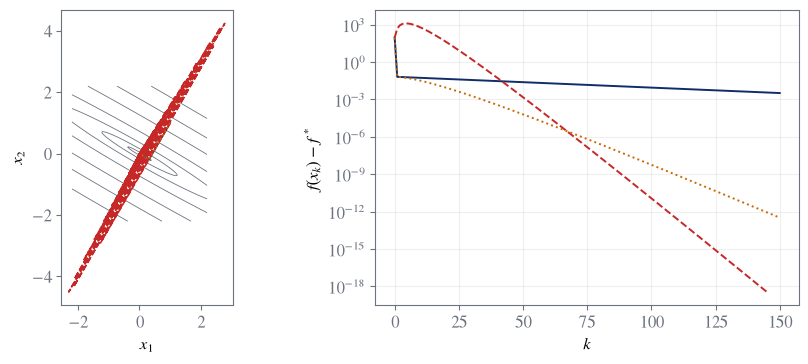

In [18]:
angle = math.pi / 6
R = np.array([[math.cos(angle), -math.sin(angle)], [math.sin(angle), math.cos(angle)]])
Qplot = R.T @ np.diag([1., 100.]) @ R
fplot = lambda x: float(x @ Qplot @ x / 2)
gplot = lambda x: Qplot @ x
x0 = np.array([1., 1.])
gd_x, gd_h = gradient_descent(fplot, gplot, x0, 1 / 100, max_iter=150)
hb_x, hb_h = momentum(fplot, gplot, x0, 4 / 121, 81 / 121, max_iter=150)
nag_x, nag_h = momentum(fplot, gplot, x0, 1 / 100, 9 / 11, max_iter=150, lookahead=True)
check('experiments: rotated eigenvalues', np.linalg.eigvalsh(Qplot), [1, 100], 1e-12)
check('experiments: rotation is orthogonal', R.T @ R, np.eye(2), 1e-14)
check('experiments: heavy ball improves eventual quadratic error', hb_h['f'][-1] < gd_h['f'][-1], True)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
grid = np.linspace(-2.2, 2.2, 240)
xx, yy = np.meshgrid(grid, grid)
zz = (Qplot[0,0] * xx**2 + 2 * Qplot[0,1] * xx*yy + Qplot[1,1] * yy**2) / 2
axes[0].contour(xx, yy, zz, levels=[0.1, 1, 5, 20, 60, 120, 220], colors=HSE['gray'], linewidths=0.6)
for h, color, style in [(gd_h,HSE['blue'],'-'),(hb_h,HSE['accent'],'--'),(nag_h,HSE['orange'],':')]:
    path = np.array(h['x'][:50])
    axes[0].plot(path[:,0], path[:,1], style, color=color, lw=1.2)
    axes[1].semilogy(range(len(h['f'])), np.maximum(h['f'],1e-20), style, color=color, lw=1.4)
axes[0].set(xlabel=r'$x_1$', ylabel=r'$x_2$', aspect='equal')
axes[1].set(xlabel=r'$k$', ylabel=r'$f(x_k)-f^*$')
axes[1].grid(alpha=0.2)
fig.tight_layout()
save(fig, 'fig_momentum')
plt.show()


### Heavy-ball stability

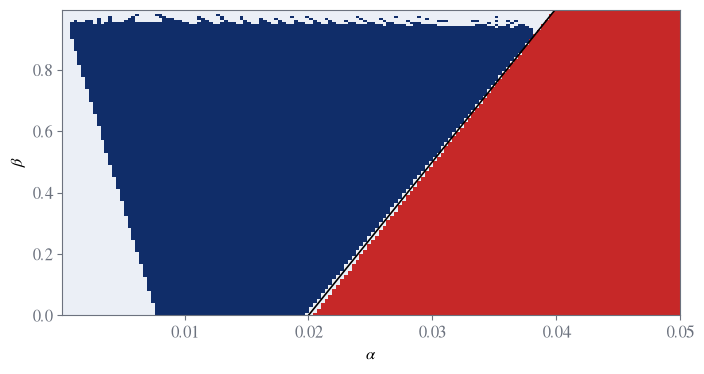

In [19]:
alphas = np.linspace(0.0001, 0.05, 160)
betas = np.linspace(0, 0.995, 150)
aa, bb = np.meshgrid(alphas, betas)
previous = np.ones((len(betas),len(alphas),2))
current = previous.copy()
lam = np.array([1.,100.])
for k in range(150):
    previous, current = current, (1 + bb[...,None] - aa[...,None] * lam) * current - bb[...,None]*previous
ratio = np.sum(lam * current**2,axis=-1) / sum(lam)
states = np.where(~np.isfinite(ratio) | (ratio > 1e6), 2, np.where(ratio<=1e-3,0,1))
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(7.2,3.9))
ax.imshow(states, origin='lower', aspect='auto', interpolation='nearest',
          extent=(alphas[0], alphas[-1], betas[0], betas[-1]),
          cmap=ListedColormap([HSE['blue'], HSE['light'], HSE['accent']]), vmin=0, vmax=2)
ax.plot(2*(1+betas)/100, betas, color='black', lw=1.2)
ax.set(xlabel=r'$\alpha$', ylabel=r'$\beta$')
fig.tight_layout()
save(fig,'fig_stability')
plt.show()


### Coordinates and CG

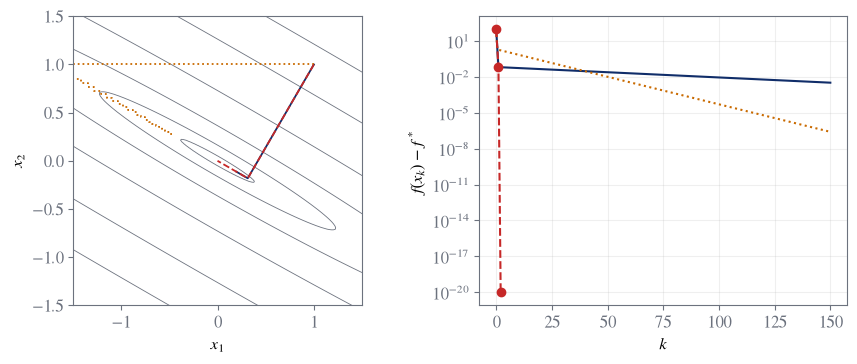

In [20]:
fdir = lambda x: float(x @ Qplot @ x / 2)
cg_x, cg_h = conjugate_gradient(Qplot, np.zeros(2), x0)
cd_x, cd_h = coordinate_descent(Qplot, np.zeros(2), x0, max_iter=300)
fig, axes = plt.subplots(1,2,figsize=(9,3.8))
axes[0].contour(xx, yy, zz, levels=[0.1,1,5,20,60,120],colors=HSE['gray'],linewidths=0.6)
for h,color,style in [(gd_h,HSE['blue'],'-'),(cd_h,HSE['orange'],':'),(cg_h,HSE['accent'],'--')]:
    path=np.array(h['x'][:50])
    axes[0].plot(path[:,0],path[:,1],style,color=color,lw=1.3)
axes[0].set(xlabel=r'$x_1$', ylabel=r'$x_2$', aspect='equal', xlim=(-1.5,1.5), ylim=(-1.5,1.5))
axes[1].semilogy(range(len(gd_h['f'])),np.maximum(gd_h['f'],1e-20),color=HSE['blue'])
axes[1].semilogy(np.arange(len(cd_h['f']))/2,np.maximum(cd_h['f'],1e-20),':',color=HSE['orange'])
axes[1].semilogy(range(len(cg_h['x'])),[max(fdir(z),1e-20) for z in cg_h['x']],'--o',color=HSE['accent'])
axes[1].set(xlabel=r'$k$', ylabel=r'$f(x_k)-f^*$')
axes[1].grid(alpha=0.2)
fig.tight_layout()
save(fig,'fig_directions')
plt.show()


### Three SGD schedules

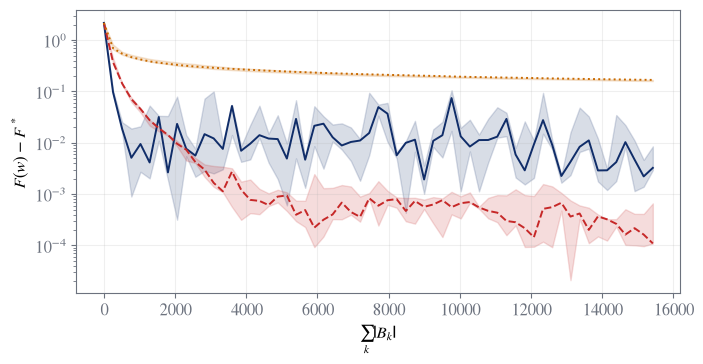

In [21]:
rng = np.random.default_rng(SEED)
n = 257
Xraw = rng.normal(size=(n,2))
Xbase = Xraw-Xraw.mean(axis=0)
Xbase /= Xbase.std(axis=0)
true_w = np.array([1.,-2.])
y = Xbase @ true_w + rng.normal(scale=0.8,size=n)
reference = np.linalg.lstsq(Xbase,y,rcond=None)[0]
optimum = np.mean((Xbase @ reference-y)**2)/2
sgd_histories = {}
fig, ax = plt.subplots(figsize=(7.2,3.8))
for schedule,color,style in [('constant',HSE['blue'],'-'),('sqrt',HSE['accent'],'--'),('inverse',HSE['orange'],':')]:
    histories=[]
    for seed in range(5):
        _, history=sgd(Xbase,y,np.zeros(2),0.2,batch_size=32,epochs=60,schedule=schedule,seed=seed)
        histories.append(history)
    sgd_histories[schedule]=histories
    curves=np.array([h['f'] for h in histories])-optimum
    lo,median,hi=np.quantile(curves,[0.25,0.5,0.75],axis=0)
    work=histories[0]['sample_gradients']
    ax.semilogy(work,np.maximum(median,1e-9),style,color=color,lw=1.4)
    ax.fill_between(work,np.maximum(lo,1e-9),np.maximum(hi,1e-9),color=color,alpha=0.16)
    check(f'experiments: {schedule} sample budget',work[-1],n*60)
    check(f'experiments: {schedule} final short batch',histories[0]['batch_lengths'][-1],1)
ax.set(xlabel=r'$\sum_k |B_k|$', ylabel=r'$F(w)-F^*$')
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig,'fig_sgd')
plt.show()


### Feature standardization

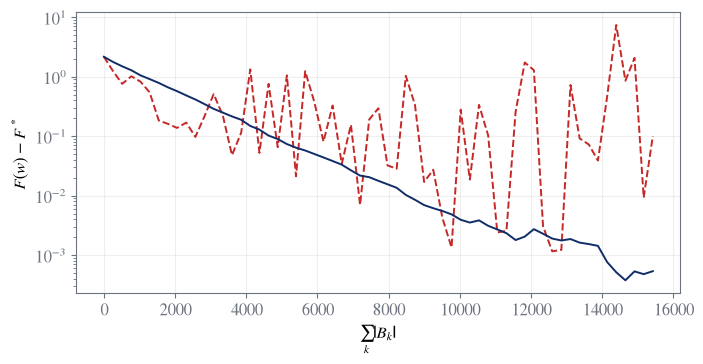

In [22]:
scale = np.array([1.,10.])
Xscaled = Xbase*scale
std = Xscaled.std(axis=0)
Xstandard = Xscaled/std
Hbefore = Xscaled.T @ Xscaled/n
Hafter = Xstandard.T @ Xstandard/n
scaled_ref = np.linalg.lstsq(Xscaled,y,rcond=None)[0]
standard_ref = np.linalg.lstsq(Xstandard,y,rcond=None)[0]
check('experiments: standardized fit predicts in original units',
      Xscaled @ (standard_ref/std), Xstandard @ standard_ref,1e-12)
check('experiments: fitted coefficients restore',standard_ref/std,scaled_ref,1e-12)
check('experiments: scaling improves condition number',np.linalg.cond(Hafter)<np.linalg.cond(Hbefore),True)
_, original_history=sgd(Xscaled,y,np.zeros(2),0.01,epochs=60)
_, standard_history=sgd(Xstandard,y,np.zeros(2),0.01,epochs=60)
fig, ax=plt.subplots(figsize=(7.2,3.8))
for h,color,style in [(original_history,HSE['accent'],'--'),(standard_history,HSE['blue'],'-')]:
    ax.semilogy(h['sample_gradients'],np.maximum(np.array(h['f'])-optimum,1e-9),style,color=color,lw=1.4)
ax.set(xlabel=r'$\sum_k |B_k|$', ylabel=r'$F(w)-F^*$')
ax.grid(alpha=0.2)
fig.tight_layout()
save(fig,'fig_scaling')
plt.show()


## 5. Handout and cheat sheet

The content is rendered into the English and Russian LaTeX sources.

In [23]:
TOKEN = re.compile(r"\{\{\s*([A-Za-z0-9.]+)\s*\}\}")


def merge_over(target, overlay):
    """The merge of access.js: objects key by key, arrays element by element, anything else replaced."""
    for key, b in overlay.items():
        a = target.get(key)
        if isinstance(a, dict) and isinstance(b, dict):
            merge_over(a, b)
        elif isinstance(a, list) and isinstance(b, list):
            for i, item in enumerate(b):
                if i < len(a) and isinstance(a[i], dict) and isinstance(item, dict):
                    merge_over(a[i], item)
                elif i < len(a):
                    a[i] = copy.deepcopy(item)
                else:
                    a.append(copy.deepcopy(item))
        else:
            target[key] = copy.deepcopy(b)
    return target


def value_at(data, path):
    node = at(data, path)
    if node is MISSING or node is None or isinstance(node, dict):
        raise KeyError(f"unresolved token {path}")
    return node


def is_num(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def decimal_str(v, digits=4):
    # toFixed of JavaScript: a tie goes away from zero
    s = str(Decimal(v).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))
    if "." in s:
        s = s.rstrip("0").rstrip(".")
    return "0" if s == "-0" else s


def tex_num(v, lang, math):
    s = decimal_str(v)
    if math:
        return s.replace(".", "{,}") if lang == "ru" else s
    s = s.replace(".", ",") if lang == "ru" else s
    return "\u2212" + s[1:] if s.startswith("-") else s


def tex_value(v, lang, math):
    """render.value of render.js: a data value as TeX (math) or as text."""
    if is_num(v):
        return tex_num(v, lang, math)
    if isinstance(v, str):
        if math:
            return re.sub(r"(\d)\.(\d)", r"\1{,}\2", v).replace(r",\ ", r";\ ") if lang == "ru" else v
        if lang == "ru" and re.fullmatch(r"-?\d+\.\d+", v):
            v = v.replace(".", ",")
        return "\u2212" + v[1:] if lang == "ru" and v.startswith("-") else v
    if isinstance(v, list) and v and all(is_num(x) for x in v):
        sep = (r";\ " if lang == "ru" else r",\ ") if math else ("; " if lang == "ru" else ", ")
        return "(" + sep.join(tex_num(x, lang, math) for x in v) + ")"
    if isinstance(v, list) and v and all(isinstance(r, list) and r and all(is_num(x) for x in r) for r in v):
        if not math:
            return " ".join(tex_value(r, lang, False) for r in v)
        rows = r" \\ ".join(" & ".join(tex_num(x, lang, True) for x in r) for r in v)
        return r"\begin{pmatrix} " + rows + r" \end{pmatrix}"
    return None


def tex_token(path, data, lang, math):
    v = value_at(data, path)
    tex = tex_value(v, lang, True)
    assert tex is not None, path
    if math:
        return tex
    text = tex_value(v, lang, False)
    # a plain nonnegative number stays text; anything with a sign or TeX goes into math
    return text if re.fullmatch(r"[0-9.,]+", text) else "$" + tex + "$"


def tex_segments(s):
    """The segmenter of render.js: $$display$$, $inline$, \\$ a literal dollar, text; a lone $ is text."""
    out, buf, i = [], "", 0
    while i < len(s):
        ch = s[i]
        if ch == "\\" and s[i + 1 : i + 2] == "$":
            buf += "\x03"
            i += 2
            continue
        if ch == "$":
            display = s[i + 1 : i + 2] == "$"
            n = 2 if display else 1
            close = s.find("$$" if display else "$", i + n)
            if close < 0:
                buf += s[i:]
                break
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", s[i + n : close]))
            i = close + n
            continue
        buf += ch
        i += 1
    if buf:
        out.append(("text", buf))
    return out


ESC = [("{", r"\{"), ("}", r"\}"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#"), ("_", r"\_"),
       ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}")]


def esc(text):
    text = text.replace("\\", "\x00")
    for a, b in ESC:
        text = text.replace(a, b)
    return text.replace("\x00", r"\textbackslash{}")


def rich(s, data, lang):
    """One content string as LaTeX: tokens become numbers and the markup \\textbf, \\emph, \\texttt."""
    # displays with only spaces between them are stacked in one: two \[ \] in a row leave an empty line
    segs = []
    for kind, seg in tex_segments(s):
        if kind == "display" and len(segs) > 1 and segs[-2][0] == "display" and segs[-1][0] == "text" \
                and not segs[-1][1].strip():
            segs.pop()
        if kind == "display" and segs and segs[-1][0] == "display":
            segs[-1][1].append(seg)
        else:
            segs.append((kind, [seg] if kind == "display" else seg))
    parts = []
    for kind, seg in segs:
        if kind == "display":
            lines = " \\\\[6pt]\n".join(b.strip() for b in seg)
            seg = lines if len(seg) == 1 else "\\begin{gathered}\n" + lines + "\n\\end{gathered}"
        if kind in ("math", "display"):
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = body.replace("\u00a0", " ").replace("\u202f", r"\,")
            assert "%" not in body and "#" not in body and "{{" not in body, seg
            display = "\n\\handoutdisplay{\n" + body.strip() + "\n}\n"
            parts.append("$" + body + "$" if kind == "math" else display)
            continue
        # tokens and code spans are set aside before escaping and restored after the markup
        toks, codes = [], []
        t = TOKEN.sub(lambda m: toks.append(m.group(1)) or f"\x01{len(toks) - 1}\x01", seg)
        t = re.sub(r"`([^`]+)`", lambda m: codes.append(esc(m.group(1))) or f"\x02{len(codes) - 1}\x02", t)
        t = esc(t).replace("\x03", r"\$").replace("\u00a0", "~").replace("\u202f", r"\,")
        t = re.sub(r"\*\*([^*]+)\*\*", r"\\textbf{\1}", t)
        t = re.sub(r"\*([^*\s][^*]*)\*", r"\\emph{\1}", t)
        t = re.sub("\x02(\\d+)\x02", lambda m: r"\texttt{" + codes[int(m.group(1))] + "}", t)
        t = re.sub("\x01(\\d+)\x01", lambda m: tex_token(toks[int(m.group(1))], data, lang, False), t)
        parts.append(t)
    out = "".join(parts)
    assert not re.search("[\x00-\x03\u00a0]", out), s
    return out


def tr(pair, data, lang, inline=False):
    """A pair as LaTeX; while a Russian string is missing, the English one is set with English hyphenation."""
    if pair.get(lang):
        return rich(pair[lang], data, lang)
    tex = rich(pair["en"], data, "en")
    if lang == "en":
        return tex
    return "\\textenglish{" + tex + "}" if inline else "\\begin{english}\n" + tex + "\n\\end{english}"


def cell_kind(cell):
    segs = tex_segments(cell)
    if len(segs) == 1 and segs[0][0] == "math":
        body = TOKEN.sub("v", segs[0][1]).strip()
        if re.fullmatch(r"v|-?\d+(\.\d+)?", body):
            return "num"
    if all(k != "text" or re.fullmatch(r"[\s,]*", v) for k, v in segs):
        return "math"
    return "text"


def cell_width(cell, data, lang):
    """Printed width of a table cell in characters; a TeX command counts as one, braces as none."""
    w = 0
    for kind, seg in tex_segments(cell):
        if kind == "text":
            seg = TOKEN.sub(lambda m: tex_value(value_at(data, m.group(1)), lang, False), seg)
            w += len(seg.replace("**", "").replace("*", "").replace("`", ""))
        else:
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = re.sub(r"\\[A-Za-z]+|\\.", "c", body).replace("{", "").replace("}", "")
            w += 2 + len(body)
    return w


# room the paragraph columns must leave: a character of a column that keeps its natural width takes at
# most this fraction of the 466.6pt text width at \small, and 2\tabcolsep between two columns takes 12pt
CHAR_SHARE = {"text": 0.012, "math": 0.010, "num": 0.010}
GAP_SHARE = 0.026


def table_spec(head, rows, data, lang):
    ncol = len(head)
    kinds, widths = [], []
    for j in range(ncol):
        body = [r[j] for r in rows]
        ks = {cell_kind(c) for c in body}
        kinds.append("num" if ks == {"num"} else "math" if ks <= {"num", "math"} else "text")
        widths.append(max(cell_width(c, data, lang) for c in [head[j]] + body))
    total = sum(widths)
    spec = ["r" if k == "num" else "l" for k in kinds]
    # a wide table gets paragraph columns for its long text columns, or for its widest column
    if total > 70:
        wide = [j for j in range(ncol) if kinds[j] == "text" and widths[j] >= 18]
        if wide:
            shares = {j: 0.9 * widths[j] / total for j in wide}
        else:
            wide = [max(range(ncol), key=lambda k: widths[k])]
            shares = {wide[0]: 0.4}
        natural = sum(CHAR_SHARE[kinds[j]] * widths[j] for j in range(ncol) if j not in wide)
        budget = 0.98 - GAP_SHARE * (ncol - 1) - natural
        # the fractions are scaled into the budget and rounded down, so their sum plus the natural
        # columns stays inside \linewidth however the estimate of the natural ones errs; a column raised
        # to the floor of 0.15 takes its room from the others
        scale = min(1.0, budget / sum(shares.values()))
        low = [j for j in wide if shares[j] * scale < 0.15]
        high = sum(shares[j] for j in wide if j not in low) * scale
        squeeze = min(1.0, (budget - 0.15 * len(low)) / high) if high else 1.0
        for j in wide:
            share = f"{0.15 if j in low else int(100 * shares[j] * scale * squeeze) / 100:g}"
            # \hspace{0pt} lets the first word of a cell be hyphenated
            spec[j] = r">{\raggedright\arraybackslash\hspace{0pt}}p{" + share + r"\linewidth}"
    return "@{}" + "".join(spec) + "@{}"


def table_tex(block, data, lang):
    pick = lambda c: c.get(lang) or c["en"]
    head, rows = [pick(c) for c in block["head"]], [[pick(c) for c in row] for row in block["rows"]]
    spec = table_spec(head, rows, data, lang)
    line = lambda cells: " & ".join(tr(c, data, lang, inline=True) for c in cells) + r" \\"
    body = [line(r) for r in block["rows"]]
    if len(body) > 10:
        return "\n".join([r"\begingroup\small", r"\begin{longtable}{" + spec + "}", r"\toprule",
                          line(block["head"]), r"\midrule", r"\endhead", *body, r"\bottomrule",
                          r"\end{longtable}", r"\endgroup"])
    return "\n".join([r"\begin{center}\small", r"\begin{tabular}{" + spec + "}", r"\toprule",
                      line(block["head"]), r"\midrule", *body, r"\bottomrule", r"\end{tabular}",
                      r"\end{center}"])


FIG_WIDTH = {'fig_momentum': 0.95, 'fig_stability': 0.9, 'fig_directions': 0.95,
             'fig_sgd': 0.9, 'fig_scaling': 0.9}
LABELS = {
    "en": {"course": "Optimization Methods", "seminar": "Seminar 04", "page": "Theory handout",
           "topic": "Accelerated Gradient Methods",
           "institution": "HSE University, Faculty of Computer Science", "year": "Academic year 2026–2027",
           "lecturer": "Course lecturer: Andrey Ignatov", "author": "Evgeny Baulin",
           "byline": "Author: Evgeny Baulin", "license": "MIT License", "kicker": "Seminar 04 cheat sheet",
           "definition": "Definition", "theorem": "Theorem", "lemma": "Lemma", "corollary": "Corollary",
           "proposition": "Proposition", "proof": "Proof", "example": "Example", "intuition": "Why",
           "trap": "Trap", "selfcheck": "Check yourself", "answer": "Answer", "convention": "Notation",
           "figure": "Figure", "statement": "Statement", "solution": "Solution",
           "board": "On the board", "students": "On your own"},
    "ru": {"course": "Методы оптимизации", "seminar": "Семинар 4", "page": "Конспект теории",
           "topic": "Ускоренные градиентные методы",
           "institution": "НИУ ВШЭ, факультет компьютерных наук", "year": "2026–2027 учебный год",
           "lecturer": "Лектор курса: Андрей Игнатов", "author": "Евгений Баулин",
           "byline": "Автор: Евгений Баулин", "license": "Лицензия MIT", "kicker": "Шпаргалка к семинару 4",
           "definition": "Определение", "theorem": "Теорема", "lemma": "Лемма", "corollary": "Следствие",
           "proposition": "Утверждение", "proof": "Доказательство", "example": "Пример",
           "intuition": "Почему",
           "trap": "Ловушка", "selfcheck": "Проверьте себя", "answer": "Ответ", "convention": "Обозначения",
           "figure": "Рисунок", "statement": "Условие", "solution": "Решение",
           "board": "У доски", "students": "Самостоятельно"},
}


def period(s):
    return s if s.endswith((".", "?", "!")) else s + "."


def block_tex(b, content, data, lang):
    t, L = b["type"], LABELS[lang]
    text = lambda pair: tr(pair, data, lang)
    title = lambda pair: tr(pair, data, lang, inline=True)
    if t == "p":
        return text(b["text"])
    if t in ("example", "intuition"):
        env = "examplebox" if t == "example" else "whybox"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "list":
        items = "\n".join("  \\item " + text(i) for i in b["items"])
        return "\\begin{itemize}\n" + items + "\n\\end{itemize}"
    if t == "figure":
        name = re.fullmatch(r"(?:figures/)?(fig_[a-z0-9_]+)(?:\.svg)?", b["src"]).group(1)
        cap = text(b["caption"]) if b.get("caption") else ""
        return f"\\handoutfigure{{{FIG_WIDTH[name]:g}}}{{{name}}}{{{cap}}}"
    if t == "table":
        return table_tex(b, data, lang)
    if t in ("definition", "theorem"):
        kind = "definition" if t == "definition" else b.get("kind", "theorem")
        label = L[kind] + (": " + title(b["title"]) if b.get("title") else "")
        env = "definitionbox" if t == "definition" else "theorembox"
        return f"\\begin{{{env}}}{{{period(label)}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t in ("proof", "trap"):
        env = t + "box"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "note":
        return f"\\begin{{notebox}}{{{title(b['title'])}}}\n{text(b['text'])}\n\\end{{notebox}}"
    if t == "selfcheck":
        return (f"\\begin{{selfcheckbox}}\n{text(b['question'])}\n"
                f"\\selfcheckanswer {text(b['answer'])}\n\\end{{selfcheckbox}}")
    if t == "problem":
        return problem_tex(b["id"], content, data, lang)
    raise ValueError(f"unknown block type {t}")


def problem_tex(pid, content, data, lang):
    P, L = content["problems"][pid], LABELS[lang]
    steps = ["  \\item " + tr(st["text"], data, lang) for st in P["steps"]]
    return "\n".join([
        f"\\problemhead{{{pid}}}{{{tr(P['title'], data, lang, inline=True)}}}{{{L[P['who']]}}}",
        f"\\textbf{{{L['statement']}.}} {tr(P['statement'], data, lang)}",
        "",
        f"\\textbf{{{L['solution']}.}}",
        # a step quotes numbers that cannot be hyphenated: let the spaces stretch instead
        "\\begingroup\\sloppy",
        "\\begin{enumerate}[label=\\textbf{\\arabic*.}, leftmargin=*]",
        *steps,
        "\\end{enumerate}",
        "\\endgroup",
        "\\begin{answerbox}",
        tr(P["answerText"], data, lang),
        "\\end{answerbox}",
    ])


def fill(template, values):
    for name, tex in values.items():
        placeholder = f"<<{name}>>"
        assert template.count(placeholder) == 1, name
        template = template.replace(placeholder, tex)
    assert "<<" not in template
    return template


def tidy(doc):
    """No trailing spaces: a text segment before a display keeps the space it ended with."""
    return "\n".join(line.rstrip() for line in doc.split("\n"))


LANGUAGE_SETUP = {
    "en": r"""\usepackage{polyglossia}
\setdefaultlanguage{english}""",
    "ru": r"""\usepackage{polyglossia}
\setdefaultlanguage{russian}
\setotherlanguage{english}
\newfontfamily\cyrillicfont{cmunrm.otf}[Ligatures=TeX, BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\newfontfamily\cyrillicfontsf{cmunss.otf}[Ligatures=TeX, BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\newfontfamily\cyrillicfonttt{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]""",
}

THEORY_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 04: theory handout (<<language>>).
% Generated by checks/04. Accelerated Gradient Methods.ipynb from web/04/js/content-*.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\documentclass[11pt,a4paper]{article}

\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=2.3cm,right=2.3cm,top=2.4cm,bottom=2.4cm,headheight=14pt]{geometry}
\usepackage{amsmath,amssymb}
\usepackage{graphicx}
\usepackage{array,booktabs,longtable}
\usepackage{enumitem}
\usepackage{xcolor}
\usepackage[most]{tcolorbox}
\usepackage{titlesec}
\usepackage{fancyhdr}
\usepackage{needspace}
\usepackage[expansion=false]{microtype}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue,citecolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}
\definecolor{hsewarm}{RGB}{253,244,232}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\titleformat{\section}{\color{hseblue}\Large\bfseries}{\thesection}{0.6em}{}
\titleformat{\subsection}{\color{hseblue}\large\bfseries}{\thesubsection}{0.6em}{}
\titlespacing*{\section}{0pt}{16pt plus 4pt minus 2pt}{8pt plus 2pt}
\titlespacing*{\subsection}{0pt}{12pt plus 3pt minus 2pt}{6pt plus 2pt}
% a heading keeps a few lines under it on its page: a breakable box right after it would otherwise leave it alone
\pretocmd{\section}{\Needspace{7\baselineskip}}{}{\errmessage{cannot patch section}}
\pretocmd{\subsection}{\Needspace{5\baselineskip}}{}{\errmessage{cannot patch subsection}}

\tcbset{handoutbox/.style={enhanced, breakable, sharp corners, boxrule=0pt, left=7pt, right=7pt, top=5pt, bottom=5pt, before skip=8pt plus 2pt, after skip=8pt plus 2pt}}
\newtcolorbox{examplebox}{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries <<labelExample>>}\ }}
\newtcolorbox{whybox}{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelWhy>>}\ }}
\newtcolorbox{answerbox}{handoutbox, colback=hsewarm, colframe=hsewarm, before upper={\textcolor{hseaccent}{\bfseries <<labelAnswer>>}\ }}
\newtcolorbox{conventionbox}{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries <<labelConvention>>}\par\smallskip}}

\newcommand{\handoutfigure}[3]{\par\medskip\noindent\begin{minipage}{\linewidth}\centering
  \includegraphics[width=#1\linewidth]{figures/#2.pdf}\par\smallskip
  \begin{minipage}{0.94\linewidth}\small\textcolor{hseblue}{\bfseries <<labelFigure>>}\ #3\end{minipage}\end{minipage}\par\medskip}
\newcommand{\problemhead}[3]{\par\bigskip\noindent{\color{hseblue}\large\bfseries #1.\ #2}\par\nopagebreak
  \noindent{\small\itshape\color{hsegray}#3}\par\nopagebreak\smallskip}
\newtcolorbox{definitionbox}[1]{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{theorembox}[1]{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{proofbox}{handoutbox, colback=white, colframe=hsegray, leftrule=1.2pt, top=3pt, bottom=3pt, before upper={\textcolor{hsegray}{\bfseries\itshape <<labelProof>>}\ }}
\newtcolorbox{notebox}[1]{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries #1}\par\smallskip}}
\newtcolorbox{trapbox}{handoutbox, colback=hsewarm, colframe=hseaccent, leftrule=2.5pt, before upper={\textcolor{hseaccent}{\bfseries <<labelTrap>>}\ }}
\newtcolorbox{selfcheckbox}{handoutbox, colback=white, colframe=hseaccent, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelSelfcheck>>}\ }}
% a display wider than the line is set as a centred paragraph that may break after a relation
\newcommand{\handoutdisplay}[1]{\sbox0{$\displaystyle #1$}\ifdim\wd0>\linewidth
  \par{\centering\binoppenalty=10000\relpenalty=0\relax$\displaystyle #1$\par}\else\[#1\]\fi}
\newcommand{\selfcheckanswer}{\par\smallskip\textcolor{hsegray}{\bfseries <<labelSelfcheckAnswer>>}\ }

\setlist[itemize]{itemsep=3pt,topsep=4pt}
\setlist[enumerate]{itemsep=3pt,topsep=4pt}
\setlength{\parindent}{0pt}
\setlength{\parskip}{5pt plus 1pt}
\setlength{\emergencystretch}{2em}
\setcounter{tocdepth}{2}

\pagestyle{fancy}
\fancyhf{}
\fancyhead[L]{\small\color{hsegray}<<headerCourse>>}
\fancyhead[R]{\small\color{hsegray}<<headerSeminar>>}
\fancyfoot[L]{\small\color{hsegray}<<footerAuthor>>}
\fancyfoot[C]{\small\thepage}
\fancyfoot[R]{\small\color{hsegray}<<footerLicense>>}
\renewcommand{\headrulewidth}{0pt}
\renewcommand{\footrulewidth}{0pt}
\fancypagestyle{plain}{\pagestyle{fancy}}

\begin{document}

\begin{center}
  {\large\color{hsegray}<<titleCourse>>\par}
  \vspace{4pt}
  {\large\bfseries\color{hseaccent}<<titleSeminar>>\par}
  \vspace{8pt}
  {\LARGE\bfseries\color{hseblue}<<titleTopic>>\par}
  \vspace{8pt}
  {\Large <<titlePage>>\par}
  \vspace{12pt}
  <<titleInstitution>>\par
  <<titleYear>>\par
  \vspace{8pt}
  <<titleLecturer>>\par
  <<titleAuthor>>\par
  Telegram: \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}\par
\end{center}

\noindent{\color{hseblue}\rule{\linewidth}{0.6pt}}

\tableofcontents

\clearpage
"""

CHEAT_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 04: one-page cheat sheet (<<language>>).
% Generated by checks/04. Accelerated Gradient Methods.ipynb from web/04/js/content-cheatsheet.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\RequirePackage{fix-cm}
\documentclass[10pt,a4paper]{article}

\usepackage{amsmath,amssymb}
\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=8mm,right=8mm,top=7mm,bottom=11mm,footskip=5.5mm]{geometry}
\usepackage{xcolor}
\usepackage{multicol}
\usepackage{enumitem}
\usepackage{ragged2e}
\usepackage{fancyhdr}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

% Page style: the author and the license in the footer.
\pagestyle{fancy}
\fancyhf{}
\renewcommand{\headrulewidth}{0pt}
\fancyfoot[L]{\scriptsize\color{hsegray}\textcopyright\ 2026 <<footerAuthor>>, \href{https://t.me/tarakan_tuc}{t.me/tarakan\_tuc}}
\fancyfoot[R]{\scriptsize\color{hsegray}<<footerLicense>>}

% Compact layout.
\setlength{\parindent}{0pt}
\setlength{\parskip}{0pt}
\setlength{\columnsep}{4.5mm}
\setlength{\columnseprule}{0.3pt}
\renewcommand{\columnseprulecolor}{\color{hselight}}
\setlength{\emergencystretch}{2em}
\setlength{\RaggedRightRightskip}{0pt plus 4em}
\binoppenalty=2000
\relpenalty=500
\setlength{\abovedisplayskip}{2pt}
\setlength{\belowdisplayskip}{2pt}
\setlist[itemize]{leftmargin=7pt, labelsep=3pt, itemsep=1.2pt, topsep=1pt, parsep=0pt, partopsep=0pt,
  label={\color{hseaccent}\scriptsize\textbullet}}

\makeatletter
\newcommand{\cssec}[1]{\par\addvspace{3.5pt}\noindent
  \colorbox{hselight}{\parbox{\dimexpr\linewidth-2\fboxsep}{\RaggedRight\hyphenpenalty=10000\color{hseblue}\bfseries\strut #1}}%
  \par\nobreak\vspace{1pt}\@afterheading}
\makeatother
\clubpenalty=10000
\widowpenalty=10000

\begin{document}
\thispagestyle{fancy}

\noindent
\begin{minipage}[b]{0.6\textwidth}
  \RaggedRight\hyphenpenalty=10000
  {\color{hseaccent}\bfseries\small <<kicker>>}\\[1pt]
  {\color{hseblue}\bfseries\Large <<title>>}
\end{minipage}\hfill
\begin{minipage}[b]{0.39\textwidth}
  \raggedleft\footnotesize
  {\bfseries <<course>>}\\
  <<institution>>, 2026--2027\\
  <<lecturer>>\\
  <<byline>>, Telegram \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}
\end{minipage}

\vspace{2pt}
{\color{hseblue}\rule{\textwidth}{0.8pt}}
\vspace{-4pt}

\fontsize{9}{<<leading>>}\selectfont
\begin{multicols}{3}
\RaggedRight
"""


def theory_tex(lang, content, data):
    h, L = content["handout"], LABELS[lang]
    topic = h["title"][lang] if h["title"].get(lang) else L["topic"]
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Theory_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang],
        "pdftitle": esc(f"{L['course']}. {L['seminar']}. {L['page']}"),
        "pdfauthor": esc(L["author"]),
        "labelExample": period(L["example"]),
        "labelWhy": period(L["intuition"]),
        "labelAnswer": period(L["answer"]),
        "labelConvention": period(L["convention"]),
        "labelFigure": period(L["figure"]),
        "labelProof": period(L["proof"]),
        "labelTrap": period(L["trap"]),
        "labelSelfcheck": period(L["selfcheck"]),
        "labelSelfcheckAnswer": period(L["answer"]),
        "headerCourse": esc(L["course"]),
        "headerSeminar": esc(L["seminar"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "titleCourse": esc(L["course"]),
        "titleSeminar": esc(L["seminar"]),
        "titleTopic": rich(topic, data, lang),
        "titlePage": esc(L["page"]),
        "titleInstitution": esc(L["institution"]),
        "titleYear": esc(L["year"]),
        "titleLecturer": esc(L["lecturer"]),
        "titleAuthor": esc(L["author"]),
    }
    out = [fill(THEORY_PREAMBLE, values), "", tr(h["intro"], data, lang), "",
           "\\begin{conventionbox}", tr(h["convention"], data, lang), "\\end{conventionbox}", ""]
    for sec in h["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += ["% " + "=" * 69, f"\\section{{{heading}}}\\label{{sec:{sec['id']}}}", ""]
        for b in sec.get("blocks", []):
            out += [block_tex(b, content, data, lang), ""]
        for sub in sec.get("subsections", []):
            heading = tr(sub["title"], data, lang, inline=True)
            out += [f"\\subsection{{{heading}}}\\label{{sub:{sub['id']}}}", ""]
            for b in sub.get("blocks", []):
                out += [block_tex(b, content, data, lang), ""]
    out.append("\\end{document}")
    return tidy("\n".join(out)) + "\n"


def split_title(title):
    """Two lines, broken at the space nearest to the middle that does not follow a short word."""
    spaces = [i for i, ch in enumerate(title) if ch == " " and len(title[:i].split(" ")[-1]) > 3]
    cut = min(spaces, key=lambda i: abs(i - len(title) / 2))
    return title[:cut] + "\\\\ " + title[cut + 1:]


def cheat_tex(lang, content, data):
    cs, L = content["cheatsheet"], LABELS[lang]
    hyphenation = "\n\\PolyglossiaSetup{russian}{hyphenmins={2,3}}" if lang == "ru" else ""
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Cheatsheet_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang] + hyphenation,
        "pdftitle": esc(f"{L['kicker']}: {cs['title'][lang]}"),
        "pdfauthor": esc(L["author"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "kicker": esc(L["kicker"]),
        "title": split_title(tr(cs["title"], data, lang, inline=True)),
        "course": esc(L["course"]),
        "institution": esc(L["institution"]),
        "lecturer": esc(L["lecturer"]),
        "byline": esc(L["byline"]),
        "leading": {"en": "11.4", "ru": "10.6"}[lang],
    }
    out = [fill(CHEAT_PREAMBLE, values), ""]
    for sec in cs["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += [f"% ---- {sec['id']}", f"\\cssec{{{heading}}}", "\\begin{itemize}"]
        out += ["  \\item " + tr(item, data, lang, inline=True) for item in sec["items"]]
        out += ["\\end{itemize}", ""]
    out += ["\\end{multicols}", "\\end{document}"]
    return tidy("\n".join(out)) + "\n"


def latex_sources(content, data):
    return {**{f"Theory_{lang}": theory_tex(lang, content, data) for lang in ("en", "ru")},
            **{f"Cheatsheet_{lang}": cheat_tex(lang, content, data) for lang in ("en", "ru")}}


assert sorted(FIG_WIDTH) == sorted(FIGURES), FIGURES
LATEX = latex_sources(merge_over(copy.deepcopy(PUBLIC["content"]), STUDENTS["content"]),
                      merge_over(copy.deepcopy(PUB), STU))
for name, text in LATEX.items():
    written = write_if_changed(THEORY / f"{name}.tex", text)
    print(f"{name}.tex: {text.count(chr(10))} lines, {'written' if written else 'unchanged'}")

Theory_en.tex: 519 lines, unchanged
Theory_ru.tex: 523 lines, unchanged
Cheatsheet_en.tex: 155 lines, unchanged
Cheatsheet_ru.tex: 160 lines, unchanged


## 6. Content consistency

Both languages, tokens, answer fields, figures, links and generated sources are checked against the saved content.

In [24]:
REQUIRE_RU = True
CYR = re.compile("[\\u0400-\\u04FF]")
TELEGRAM = "https://t.me/tarakan_tuc"
NOT_TEXT = {"id", "who", "ref", "type", "kind", "src", "v", "keys", "pages"}
PROBLEM_IDS = [f"{b}{i}" for b in "ABC" for i in (1, 2, 3)]
TEXT_SUFFIXES = {".html", ".css", ".js", ".json", ".svg", ".tex", ".txt", ".md", ".py", ".sh", ".ipynb",
                 ".service", ".timer"}


def visible(node, where, problems, untranslated):
    """(where, lang, text) for every {"en", "ru"} pair; a pair without ru goes to untranslated,
    any other shape of visible text to problems."""
    if isinstance(node, dict):
        if "en" in node or "ru" in node:
            if "en" not in node or not set(node) <= {"en", "ru"}:
                problems.append(f"{where}: keys {sorted(node)}")
            if "ru" not in node:
                untranslated.append(where)
            for lang in ("en", "ru"):
                if lang not in node:
                    continue
                if not isinstance(node[lang], str) or not node[lang].strip():
                    problems.append(f"{where}: empty or non-string '{lang}'")
                else:
                    yield where, lang, node[lang]
            return
        for k, v in node.items():
            yield from visible(v, f"{where}.{k}", problems, untranslated)
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from visible(v, f"{where}[{i}]", problems, untranslated)
    elif isinstance(node, str) and where.rsplit(".", 1)[-1].split("[")[0] not in NOT_TEXT:
        problems.append(f"{where}: a bare string")


def cyrillic_outside_ru(node, where):
    """Paths of Cyrillic text other than the ru half of a pair and data leaves named ...Ru."""
    if isinstance(node, dict):
        for k, v in node.items():
            if CYR.search(k):
                yield f"{where}: the key {k}"
            if (k == "ru" and "en" in node) or (where.startswith("data") and k.endswith("Ru")):
                continue
            yield from cyrillic_outside_ru(v, f"{where}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from cyrillic_outside_ru(v, f"{where}[{i}]")
    elif isinstance(node, str) and CYR.search(node):
        yield where


def resolves(path, roots):
    return any(at(root, path) is not MISSING and not isinstance(at(root, path), dict) for root in roots)


def segments(text):
    """('text' | 'math' | 'display', piece) in order; None when a $ is not closed."""
    out, buf, i = [], "", 0
    while i < len(text):
        if text[i] == "\\" and text[i + 1:i + 2] == "$":
            buf += "$"
            i += 2
            continue
        if text[i] == "$":
            display = text[i + 1:i + 2] == "$"
            width = 2 if display else 1
            close = text.find("$$" if display else "$", i + width)
            if close < 0:
                return None
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", text[i + width:close]))
            i = close + width
            continue
        buf += text[i]
        i += 1
    if buf:
        out.append(("text", buf))
    return out


def stray_digits(kind, piece):
    piece = TOKEN.sub("", piece)
    if kind == "text":
        piece = re.sub(r"\b[A-Z]\d\b", "", piece)
        piece = re.sub(r"\b[Tt]asks? \d+(?:(?:, | and | to |–)\d+)*", "", piece)
        piece = re.sub(r"\b[Зз]адач\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|–)\d+)*", "", piece)
        piece = re.sub(r"\b202[67]\b", "", piece)
        return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if m not in {"0", "1", "2", "4", SEMINAR}]
    return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if len(m) > 1]


def pdf_pages(path):
    """Page count from the /Type /Pages dictionaries, also inside compressed object streams."""
    raw = Path(path).read_bytes()
    blobs = [raw]
    for m in re.finditer(rb"stream\r?\n(.*?)\r?\nendstream", raw, re.S):
        try:
            blobs.append(zlib.decompressobj().decompress(m.group(1)))
        except zlib.error:
            pass
    counts = []
    for b in blobs:
        for d in re.findall(rb"<<(?:[^<>]|<<[^<>]*>>)*?/Type\s*/Pages\b(?:[^<>]|<<[^<>]*>>)*?>>", b):
            counts += [int(c) for c in re.findall(rb"/Count\s+(\d+)", d)]
    return max(counts) if counts else None

In [25]:
DOCS = {}
for name in ("public", "students", "teacher"):
    path = CONTENT / f"{name}.json"
    try:
        DOCS[name] = strict_json(path)
        error = None
    except (OSError, ValueError) as err:
        DOCS[name], error = {}, str(err)
    check(f"consistency: {name}.json is strict JSON", error or "ok", "ok")
    check(f"consistency: {name}.json has id seminar-04", DOCS[name].get("id"), "seminar-04")
    check(f"consistency: {name}.json has Cyrillic only in ru strings and data leaves named ...Ru",
          [w for k, v in DOCS[name].items() for w in cyrillic_outside_ru(v, k)], [])
check("consistency: public.json holds only the numbers, the public text is in web/04/js",
      sorted(DOCS["public"]), ["data", "id"])

public_content, top_keys = {}, []
for path in CONTENT_FILES:
    try:
        obj, outside = marked_json(path)
        error = None
    except (OSError, ValueError) as err:
        obj, outside, error = {}, "", str(err)
    check(f"consistency: {path.name} has strict JSON between the markers", error or "ok", "ok")
    check(f"consistency: {path.name} has no Cyrillic outside the JSON", CYR.search(outside) is None, True)
    top_keys += list(obj)
    public_content.update(obj)
check("consistency: the content files hold seminar, main, problems, handout and cheatsheet, one each",
      top_keys, ["seminar", "main", "problems", "handout", "cheatsheet"])
check("consistency: the public content has Cyrillic only in ru strings",
      list(cyrillic_outside_ru(public_content, "content")), [])
DOCS["public"]["content"] = public_content

LABEL = {"public": "the public content", "students": "students.json", "teacher": "teacher.json"}
data = {name: DOCS[name].get("data", {}) for name in DOCS}
roots = {"public": [data["public"]], "students": [data["public"], data["students"]],
         "teacher": [data["public"], data["students"], data["teacher"]]}
filled, untranslated_total = [], 0
for name, doc in DOCS.items():
    problems, untranslated = [], []
    texts = list(visible(doc.get("content", {}), f"{name}.content", problems, untranslated))
    pairs = sum(lang == "en" for _, lang, _ in texts)
    if texts:
        filled.append(f"{name}: {pairs} strings, untranslated: {len(untranslated)}")
    untranslated_total += len(untranslated)
    label = LABEL[name]
    check(f"consistency: {label}: every visible string is an {{en, ru}} pair of non-empty strings",
          problems, [])
    check(f"consistency: {label}: every pair has its ru", untranslated if REQUIRE_RU else [], [])
    check(f"consistency: {label}: no Cyrillic in en", [w for w, lang, s in texts
                                                       if lang == "en" and CYR.search(s)], [])
    tokens = sorted({f"{w}.{lang}: {t}" for w, lang, s in texts for t in TOKEN.findall(s)
                     if t.startswith("TODO.") or not resolves(t, roots[name])})
    check(f"consistency: {label}: every token resolves in the data it may see", tokens, [])
    digits = []
    for w, lang, s in texts:
        parts = segments(s)
        if parts is None:
            digits.append(f"{w}.{lang}: a $ is not closed")
            continue
        for kind, piece in parts:
            if stray_digits(kind, piece):
                digits.append(f"{w}.{lang}: {kind} {stray_digits(kind, piece)}")
    check(f"consistency: {label}: no literal numbers outside tokens", digits, [])
    markup = [f"{w}.{lang}" for w, lang, s in texts if re.search(r"<[a-zA-Z/!]|https?://|www\.", s)]
    check(f"consistency: {label}: no HTML and no links in the text", markup, [])

pub_c, stu_c, tea_c = (DOCS[n].get("content", {}) for n in ("public", "students", "teacher"))
pub_problems = pub_c.get("problems", {})
known = list(pub_problems) or PROBLEM_IDS
pub_specs, stu_specs = data["public"].get("answers", {}), data["students"].get("answers", {})
specs = {**pub_specs, **stu_specs}
check("consistency: the public problems are A1 to C3", sorted(pub_problems) if pub_problems else PROBLEM_IDS,
      PROBLEM_IDS)
parts_off = []
for pid, P in pub_problems.items():
    parts = [(part.get("id"), part.get("ref")) for part in P.get("answers", [])]
    if parts != [(k, f"answers.{pid}.{k}") for k in specs.get(pid, {})]:
        parts_off.append(pid)
    for _, ref in parts:
        spec = at(data["public" if pid in pub_specs else "students"], str(ref))
        if not isinstance(spec, dict) or "type" not in spec:
            parts_off.append(f"{pid}: {ref}")
if pub_problems:
    parts_off += [f"{pid}: specs without a problem" for pid in specs if pid not in pub_problems]
check("consistency: one answer part per answers.* spec, in order, each resolving to a spec", parts_off, [])
board = [pid for pid, P in pub_problems.items() if P.get("who") == "board"]
check("consistency: the board problems A1, B1 and C1 are public in full, with their answer specs; "
      "the other problems keep specs and solutions locked",
      [board, sorted(pub_specs), sorted(p for p in pub_problems if "steps" in pub_problems[p]),
       sorted(stu_specs), sorted(stu_c.get("problems", {}))],
      [["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A2", "A3", "B2", "B3", "C2", "C3"],
       ["A2", "A3", "B2", "B3", "C2", "C3"]])
check("consistency: students and teacher problems exist publicly",
      [p for p in list(stu_c.get("problems", {})) + list(tea_c.get("teacher", {}).get("problems", {}))
       if p not in known], [])
blocks = data["public"]["timeline"]["blocks"]
check("consistency: public main.blocks are timeline.blocks, in order",
      list(pub_c.get("main", {}).get("blocks", {})) or blocks, blocks)
other_blocks = [*stu_c.get("main", {}).get("blocks", {}), *tea_c.get("teacher", {}).get("blocks", {})]
check("consistency: students and teacher blocks are among timeline.blocks",
      [b for b in other_blocks if b not in blocks], [])
pub_figs = sorted({d["src"] for d in nodes(pub_c) if isinstance(d.get("src"), str)})
fig_refs = {d["src"] for c in (pub_c, stu_c) for d in nodes(c) if isinstance(d.get("src"), str)}
check("consistency: every figure the public and students content name exists as SVG and PDF",
      sorted(s for s in fig_refs if s not in FIGURES or not (FIG_DIR / f"{s}.svg").is_file()
             or not (FIG_DIR / f"{s}.pdf").is_file()), [])
web_figs = WEB / "figures"
check("consistency: web/04/figures holds the figures of the public content, as the same SVG",
      [p.name for p in sorted(web_figs.iterdir()) if p.name != ".DS_Store"] if web_figs.is_dir() else [],
      [f"{s}.svg" for s in pub_figs])
check("consistency: web/04/figures/*.svg equal the handout's",
      [s for s in pub_figs if not (web_figs / f"{s}.svg").is_file()
       or (web_figs / f"{s}.svg").read_bytes() != (FIG_DIR / f"{s}.svg").read_bytes()], [])
check("consistency: the teacher content names no figure",
      sorted(d["src"] for d in nodes(tea_c) if isinstance(d.get("src"), str)), [])
embedded = {d.get("id") for d in nodes(stu_c.get("handout", {})) if d.get("type") == "problem"}
check("consistency: every problem the handout embeds exists", sorted(embedded - set(known)), [])

web_hits = []
for path in sorted(WEB.rglob("*")):
    if not path.is_file() or path.suffix not in TEXT_SUFFIXES:
        continue
    rel = path.relative_to(WEB).as_posix()
    text = path.read_text(encoding="utf-8", errors="replace")
    if path.suffix != ".svg":
        for needle in ("fetch(", "XMLHttpRequest", "import ", "export "):
            allowed = 1 if (rel == "js/access.js" and needle == "fetch(") else 0
            if text.count(needle) > allowed:
                web_hits.append(f"{rel}: {needle!r} x{text.count(needle)}")
        urls = re.findall(r"https?://[^\s\"'<>)\\]+", text)
        web_hits += [f"{rel}: {url}" for url in urls if url != TELEGRAM]
    if path in CONTENT_FILES:
        text = re.sub(r"/\*JSON-BEGIN\*/.*/\*JSON-END\*/", "", text, flags=re.S)
    if CYR.search(text) and rel != f"data/seminar{SEMINAR}_data.js":
        web_hits.append(f"{rel}: Cyrillic")
check("consistency: web/04 has no fetch (but one in js/access.js), XMLHttpRequest, import, export, "
      "foreign URL, or Cyrillic outside the data file and the JSON of the content files", web_hits, [])
cyr_files = [p.relative_to(THEORY).as_posix() for p in sorted(THEORY.rglob("*"))
             if p.is_file() and p.suffix in TEXT_SUFFIXES and not p.name.endswith("_ru.tex")
             and not (p.parent == CONTENT and p.suffix == ".json")
             and CYR.search(p.read_text(encoding="utf-8", errors="ignore"))]
check("consistency: Cyrillic in the theory folder only in content/*.json and *_ru.tex", cyr_files, [])
check("consistency: the five figures are written", sorted(FIGURES),
      ["fig_directions", "fig_momentum", "fig_scaling", "fig_sgd", "fig_stability"])

# the LaTeX sources against a generation from the files as they are now, then their PDFs
try:
    fresh = latex_sources(merge_over(copy.deepcopy(public_content), DOCS["students"].get("content", {})),
                          merge_over(copy.deepcopy(data["public"]), data["students"]))
    stale = [name for name, text in fresh.items() if not (THEORY / f"{name}.tex").is_file()
             or (THEORY / f"{name}.tex").read_bytes() != text.encode("utf-8")]
except (KeyError, TypeError, ValueError, AssertionError) as err:
    stale = [f"no generation: {err!r}"]
check("consistency: the four LaTeX files on disk equal a fresh generation", stale, [])
INPUTREF = re.compile(r"\\input\{([^{}]+)\}")
FIGREF = re.compile(r"\\handoutfigure\{[^{}]*\}\{([^{}]+)\}")
pdf_problems, pages = [], {}
for name in LATEX:
    tex, pdf, log = (THEORY / f"{name}{suffix}" for suffix in (".tex", ".pdf", ".log"))
    if not pdf.is_file():
        pdf_problems.append(f"{name}.pdf missing")
        continue
    text = tex.read_text(encoding="utf-8") if tex.is_file() else ""
    sources = [tex] + [THEORY / f"{s.removesuffix('.tex')}.tex" for s in INPUTREF.findall(text)]
    sources += [FIG_DIR / f"{n}.pdf" for n in FIGREF.findall(text)]
    for source in sources:
        if not source.is_file():
            pdf_problems.append(f"{name}.pdf: {source.relative_to(THEORY).as_posix()} missing")
        elif pdf.stat().st_mtime < source.stat().st_mtime - 2:
            pdf_problems.append(f"{name}.pdf older than {source.relative_to(THEORY).as_posix()}")
    pages[name] = pdf_pages(pdf)
    if name.startswith("Cheatsheet") and pages[name] != 1:
        pdf_problems.append(f"{name}.pdf has {pages[name]} pages")
    if log.is_file() and "Overfull \\hbox" in log.read_text(encoding="utf-8", errors="ignore"):
        pdf_problems.append(f"{name}.log: Overfull \\hbox")
check("consistency: every PDF is newer than its sources, the cheat sheets have one page and no log "
      "reports an overfull box", pdf_problems, [])

rows = [c for c in CHECKS if c["check"].startswith("consistency:")]
print(f"{sum(c['passed'] for c in rows)} of {len(rows)} consistency checks passed")
print("strings:", "; ".join(filled) if filled else "none")
print(f"untranslated: {untranslated_total}")
print("pages:", ", ".join(f"{name} {n}" for name, n in pages.items()) if pages else "no PDF")
for c in rows:
    if not c["passed"]:
        print(f"  {c['check']}: {c['detail']}")

56 of 56 consistency checks passed
strings: public: 180 strings, untranslated: 0; students: 146 strings, untranslated: 0; teacher: 1 strings, untranslated: 0
untranslated: 0
pages: Theory_en 12, Theory_ru 13, Cheatsheet_en 1, Cheatsheet_ru 1


## 7. Summary

In [26]:
failed = [c for c in CHECKS if not c['passed']]
print(f"{len(CHECKS) - len(failed)} of {len(CHECKS)} checks passed")
for c in failed:
    print(f"FAILED: {c['check']}: {c['detail']} != {c['expected']}")


264 of 264 checks passed


## 8. Export

Only public numerical data are exported to the page.

In [27]:
GENERATED = f"Generated by checks/{NOTEBOOK}. Do not edit by hand."
LICENCE = ["SPDX-License-Identifier: MIT", "Copyright (c) 2026 Evgeny Baulin"]
payload = json.dumps(strict_json(CONTENT / "public.json")["data"], indent=1, ensure_ascii=True)
data_js = ("".join(f"// {line}\n" for line in [GENERATED, *LICENCE])
           + "window.SEM = window.SEM || {};\nwindow.SEM.data = /*JSON-BEGIN*/" + payload + "/*JSON-END*/;\n")
data_path = WEB / "data" / f"seminar{SEMINAR}_data.js"
old = data_path.read_text(encoding="utf-8") if data_path.is_file() else ""
size = len(data_js.encode("utf-8"))
if write_if_changed(data_path, data_js):
    diff = list(difflib.unified_diff(old.splitlines(), data_js.splitlines(), lineterm="", n=0))
    added = sum(1 for line in diff if line.startswith("+") and not line.startswith("+++"))
    removed = sum(1 for line in diff if line.startswith("-") and not line.startswith("---"))
    print(f"{data_path.name}: rewritten (+{added} −{removed} lines, {size} bytes)")
else:
    print(f"{data_path.name}: unchanged ({size} bytes)")

seminar04_data.js: unchanged (4450 bytes)
